# Chapitre 5 - Exercices 5.1 à 5.6

Ce notebook traite six exercices sur les fondements de l'ingénierie des prompts (cours 1 et 2) :

- **5.1** : combien coûte un prompt ? (calcul de coût mensuel, part des exemples, leviers d'économie) ;
- **5.2** : combien d'exemples ? rendement marginal du few-shot et choix de $k$ optimal ;
- **5.3** : calibration contextuelle, corriger les biais d'un prompt few-shot (mini-lab) ;
- **5.4** : réécrire le gabarit ChatML à la main et débusquer un gabarit bogué ;
- **5.5** : budget de contexte : cache KV, mémoire GPU et nombre de requêtes simultanées (calcul) ;
- **5.6** : « perdu au milieu » : test statistique et remède par la position de la question.

In [1]:
import time
import math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from aie import llm
from aie import ch05_prompts as P
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN,
                          LIGHT, annotate_bars, subtitle, finish)

set_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 90)
tok = P._tokenizer(llm.SMALL)
pool, test = P.split_intents(4, seed=0)
y_true = [y for _, y in test]

## Exercice 5.1 : Combien coûte un prompt ?

**Énoncé.** Un assistant de service client reçoit **2 millions de requêtes par mois**. Chaque
requête contient : un prompt système de 400 tokens, 6 exemples de 60 tokens chacun, un message
utilisateur de 80 tokens en moyenne ; la réponse fait 150 tokens en moyenne. Tarifs de l'API :
2,50 \$ par million de tokens d'entrée et 10 \$ par million de tokens de sortie.

1. Calculer le coût mensuel et la part due aux exemples.
2. Évaluer trois leviers : (a) passer à 2 exemples ; (b) un format d'exemples 30 % plus compact ;
   (c) une **mise en cache du préfixe** (système + exemples, identiques pour toutes les requêtes)
   facturée à 50 % du prix normal ; (d) demander des réponses deux fois plus courtes.
3. Vérifier l'ordre de grandeur « 60 tokens par exemple » avec le tokenizer de Qwen sur les
   exemples du cours.

**Rappels.** Le coût d'un appel est linéaire en tokens d'entrée et de sortie :
$C = n_\text{in} c_\text{in} + n_\text{out} c_\text{out}$, et tout ce qui est dans le prompt
(système, exemples) est payé **à chaque requête** (section *In-Context Learning*, cours 1). Les
tokens de sortie coûtent typiquement 3 à 5 fois plus cher que ceux d'entrée.

**Solution.**

1. Entrée par requête : $400 + 6 \times 60 + 80 = 840$ tokens, soit $840 \times 2{,}5 \cdot 10^{-6}
   = 0{,}0021$ \$ ; sortie : $150 \times 10^{-5} = 0{,}0015$ \$. Total : $0{,}0036$ \$ par requête, donc
   **7 200 \$ par mois**. Les exemples (360 tokens) coûtent $360 \times 2{,}5\cdot10^{-6} \times 2\cdot10^6 = 1\,800$ \$,
   soit **25 %** de la facture.
2. Chaque levier se calcule de la même façon (code ci-dessous). Le cache du préfixe agit sur
   760 tokens par requête ; réduire la sortie agit sur le poste le plus cher par token.

In [2]:
def cout_mensuel(n_sys=400, n_ex=6, tok_ex=60, n_user=80, n_out=150, req=2e6, c_in=2.5e-6, c_out=10e-6,
                 remise_cache=0.0):
    prefixe = n_sys + n_ex * tok_ex
    entree = prefixe * (1 - remise_cache) + n_user
    postes = {"système": n_sys * (1 - remise_cache) * c_in * req,
              "exemples": n_ex * tok_ex * (1 - remise_cache) * c_in * req,
              "message utilisateur": n_user * c_in * req,
              "réponse": n_out * c_out * req}
    return postes

scen = {
    "référence": cout_mensuel(),
    "(a) 2 exemples": cout_mensuel(n_ex=2),
    "(b) format -30 %": cout_mensuel(tok_ex=42),
    "(c) cache du préfixe": cout_mensuel(remise_cache=0.5),
    "(d) réponses /2": cout_mensuel(n_out=75),
}
tab = pd.DataFrame(scen).T
tab["total"] = tab.sum(axis=1)
tab["économie"] = (1 - tab.total / tab.total["référence"]).map(lambda v: f"{100 * v:.0f} %")
tab.round(0)

,système,exemples,message utilisateur,réponse,total,économie
référence,2000.0,1800.0,400.0,3000.0,7200.0,0 %
(a) 2 exemples,2000.0,600.0,400.0,3000.0,6000.0,17 %
(b) format -30 %,2000.0,1260.0,400.0,3000.0,6660.0,7 %
(c) cache du préfixe,1000.0,900.0,400.0,3000.0,5300.0,26 %
(d) réponses /2,2000.0,1800.0,400.0,1500.0,5700.0,21 %


**Vérification** graphique et mesure de la taille réelle d'un exemple.

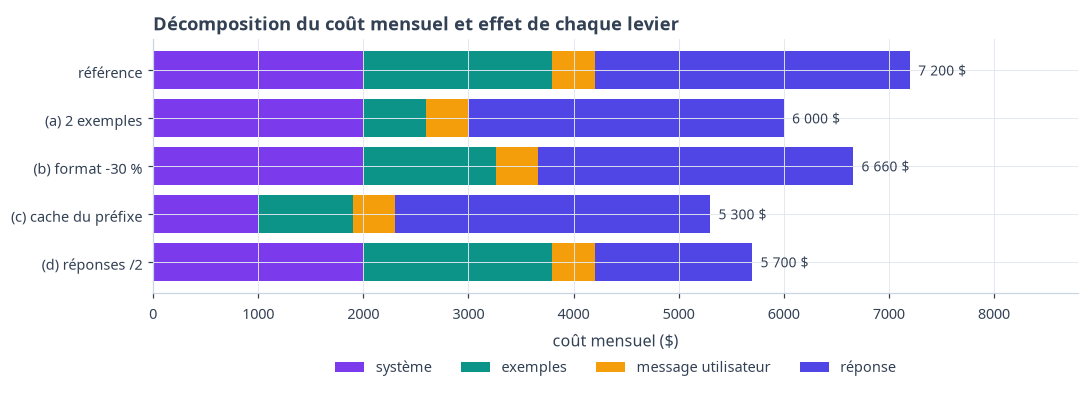

exemples du cours : 22.9 tokens en moyenne (min 17, max 29)
en tours de conversation, + ~10 tokens de gabarit par exemple (2 messages x ~5 tokens)


In [3]:
fig, ax = plt.subplots(figsize=(10, 3.8))
left = np.zeros(len(tab))
for col, c in zip(["système", "exemples", "message utilisateur", "réponse"], [VIOLET, TEAL, AMBER, INDIGO]):
    ax.barh(tab.index, tab[col], left=left, color=c, label=col)
    left += tab[col].values
for i, t in enumerate(tab.total):
    ax.text(t + 80, i, f"{t:,.0f} $".replace(",", " "), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 8800)
ax.set_xlabel("coût mensuel ($)")
ax.set_title("Décomposition du coût mensuel et effet de chaque levier")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4)
finish(fig)
plt.show()

ex_tokens = [P.count_tokens(f"Message : {x}\nCatégorie : {y}") for x, y in pool]
print(f"exemples du cours : {np.mean(ex_tokens):.1f} tokens en moyenne (min {min(ex_tokens)}, max {max(ex_tokens)})")
print(f"en tours de conversation, + ~{2 * 5} tokens de gabarit par exemple (2 messages x ~5 tokens)")

Nos exemples de classification sont courts (une vingtaine de tokens) ; 60 tokens correspond à
des exemples plus riches (un ticket et sa réponse type). Le calcul montre que **la réponse**
est ici le premier poste : demander de la concision (cours 3, section 1) rapporte autant que
d'optimiser les exemples. Le cache de préfixe, proposé par plusieurs fournisseurs, rend les
longs préfixes stables (système + exemples) beaucoup moins chers : raison de plus pour mettre
les parties fixes **au début** du prompt.

> **À retenir.** Tout ce qui est fixe dans le prompt est payé à chaque appel ; un calcul de
> coût poste par poste indique quel levier actionner (nombre d'exemples, format, cache, longueur
> des réponses).

## Exercice 5.2 : Combien d'exemples ? Rendement marginal du few-shot

**Énoncé.** Sur la tâche d'intentions, mesurer la précision moyenne pour
$k \in \{0, 2, 4, 8, 16\}$ (exemples en tours de conversation, 3 tirages par $k$). Ajuster un
modèle de saturation $\text{acc}(k) = a - b\,e^{-k/\tau}$. On suppose qu'une bonne
classification rapporte 0,002 \$ (ticket bien routé) et qu'un exemple coûte 30 tokens d'entrée
à 2,5 \$ par million. Quel $k$ maximise le gain net par requête ? Que se passe-t-il si une
erreur coûte beaucoup plus cher ?

**Rappels.** L'apprentissage en contexte améliore la précision avec des rendements
décroissants (cours 1, section 3) ; chaque exemple augmente le coût linéairement
(exercice 5.1). Le gain net par requête vaut $G(k) = g\,\text{acc}(k) - k\,t\,c_\text{in}$.

**Solution.** On mesure la courbe, on l'ajuste par moindres carrés non linéaires, puis on
maximise $G(k)$ sur une grille. La dérivée $G'(k) = g\,\frac{b}{\tau} e^{-k/\tau} - t\,c_\text{in}$
s'annule en $k^\star = \tau \ln\!\big(\frac{g\,b}{\tau\,t\,c_\text{in}}\big)$ : $k^\star$ croît
**logarithmiquement** avec la valeur d'une bonne réponse.

In [4]:
from scipy.optimize import curve_fit

ks = [0, 2, 4, 8, 16]
mes = []
for k in ks:
    for s in range(3 if k else 1):
        mes.append(dict(k=k, tirage=s, acc=P.accuracy_at_k(test, P.sample_shots(pool, k, seed=s))))
mes = pd.DataFrame(mes)
moy = mes.groupby("k").acc.mean()

def sat(k, a, b, tau):
    return a - b * np.exp(-k / tau)

(a, b, tau), _ = curve_fit(sat, mes.k, mes.acc, p0=[0.75, 0.3, 4], bounds=([0, 0, 0.3], [1, 1, 50]))
print(f"ajustement : a = {a:.3f}, b = {b:.3f}, tau = {tau:.2f}")
moy.round(3)

ajustement : a = 0.731, b = 0.251, tau = 4.86


k
0     0.475
2     0.567
4     0.625
8     0.675
16    0.725
Name: acc, dtype: float64

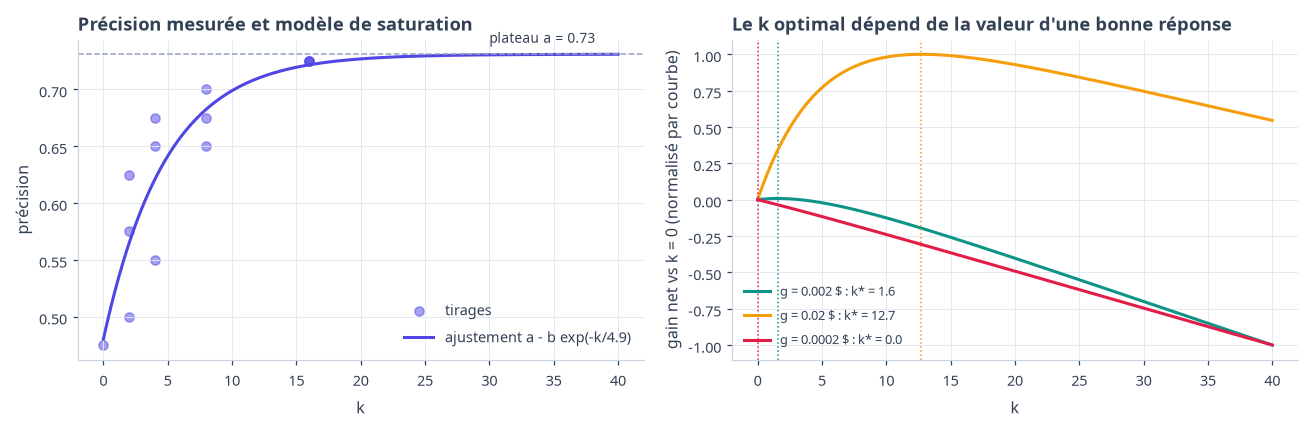

In [5]:
kk = np.linspace(0, 40, 401)
t_ex, c_in = 30, 2.5e-6
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.scatter(mes.k, mes.acc, color=INDIGO, alpha=0.5, label="tirages")
ax.plot(kk, sat(kk, a, b, tau), color=INDIGO, label=f"ajustement a - b exp(-k/{tau:.1f})")
ax.axhline(a, color=GRAY, ls="--", lw=1)
ax.text(30, a + 0.01, f"plateau a = {a:.2f}", fontsize=9)
ax.set_xlabel("k")
ax.set_ylabel("précision")
ax.set_title("Précision mesurée et modèle de saturation")
ax.legend(loc="lower right")
ax = axes[1]
for g, c in [(0.002, TEAL), (0.02, AMBER), (0.0002, ROSE)]:
    G = g * sat(kk, a, b, tau) - kk * t_ex * c_in
    kstar = kk[np.argmax(G)]
    dG = G - G[0]
    ax.plot(kk, dG / np.abs(dG).max(), color=c, label=f"g = {g} $ : k* = {kstar:.1f}")
    ax.axvline(kstar, color=c, ls=":", lw=1)
ax.set_xlabel("k")
ax.set_ylabel("gain net vs k = 0 (normalisé par courbe)")
ax.set_title("Le k optimal dépend de la valeur d'une bonne réponse")
ax.legend(fontsize=8.5, loc="lower left")
finish(fig)
plt.show()

**Lecture.** Quand une bonne réponse vaut peu (0,0002 \$), quelques exemples suffisent, voire
aucun ; quand elle vaut cher (0,02 \$, par exemple une erreur de routage qui coûte un appel
humain), on a intérêt à aller jusqu'au plateau de la courbe. Attention : avec 40 messages de
test et 3 tirages, l'ajustement est bruité ; et au-delà de 16 exemples on **extrapole**.

> **À retenir.** Le nombre d'exemples se choisit par une analyse coût / bénéfice sur une courbe
> **mesurée** : $k^\star$ ne croît que logarithmiquement avec la valeur d'une bonne réponse.

## Exercice 5.3 : Calibration contextuelle

**Énoncé.** Au cours 1, la présentation « en ligne » des exemples rendait le modèle instable et
biaisé vers certaines étiquettes. Zhao et al. (2021) proposent la **calibration contextuelle** :
on mesure les probabilités que le prompt attribue aux étiquettes pour une entrée **vide de
sens** (« N/A », chaîne vide, « [MASK] »), puis on divise les probabilités de chaque vraie
entrée par ce biais. Implémenter la méthode et mesurer son effet sur 5 ordres d'un même jeu de
8 exemples.

**Rappels.** Biais de récence et d'étiquette majoritaire (cours 1, section 4). Si $\hat p(y\mid x)$
est la distribution du modèle et $\bar p_\text{cf}(y)$ la moyenne des distributions sur les entrées
vides, la prédiction calibrée est
$$\tilde y = \arg\max_y \frac{\hat p(y\mid x)}{\bar p_\text{cf}(y)},$$
c'est-à-dire une transformation affine diagonale $W = \mathrm{diag}(\bar p_\text{cf})^{-1}$
appliquée aux probabilités, puis renormalisation.

**Solution.** Pour un prompt donné (exemples et ordre fixés), on calcule $\bar p_\text{cf}$
(3 appels), puis on corrige chaque prédiction. Le coût est négligeable : 3 appels par prompt.

In [6]:
base8 = P.sample_shots(pool, 8, seed=2)
rng = np.random.default_rng(0)
CONTENT_FREE = ["N/A", "", "[MASK]"]
rows = []
for perm_id in range(5):
    perm = list(range(8)) if perm_id == 0 else list(rng.permutation(8))
    shots = [base8[j] for j in perm]
    p_cf = np.mean([P.classify(cf, shots, shot_format="inline")[1] for cf in CONTENT_FREE], axis=0)
    labs, probs = P.predictions(test, shots, shot_format="inline")
    cal = probs / p_cf
    cal = cal / cal.sum(axis=1, keepdims=True)
    pred_cal = [P.INTENT_LABELS[i] for i in cal.argmax(1)]
    rows.append(dict(ordre=perm_id, biais_cf=np.round(p_cf, 2), avant=np.mean([a == b for a, b in zip(labs, y_true)]),
                     apres=np.mean([a == b for a, b in zip(pred_cal, y_true)]),
                     etiquettes_distinctes_avant=len(set(labs)), etiquettes_distinctes_apres=len(set(pred_cal))))
calib = pd.DataFrame(rows)
calib

,ordre,biais_cf,avant,apres,etiquettes_distinctes_avant,etiquettes_distinctes_apres
0,0,"[0.21, 0.48, 0.14, 0.18]",0.250,0.325,1,4
1,1,"[0.41, 0.13, 0.05, 0.41]",0.500,0.450,3,4
2,2,"[0.42, 0.15, 0.12, 0.3]",0.525,0.500,3,4
3,3,"[0.2, 0.65, 0.04, 0.12]",0.350,0.375,3,4
4,4,"[0.33, 0.25, 0.11, 0.31]",0.450,0.475,3,4


**Vérification** graphique.

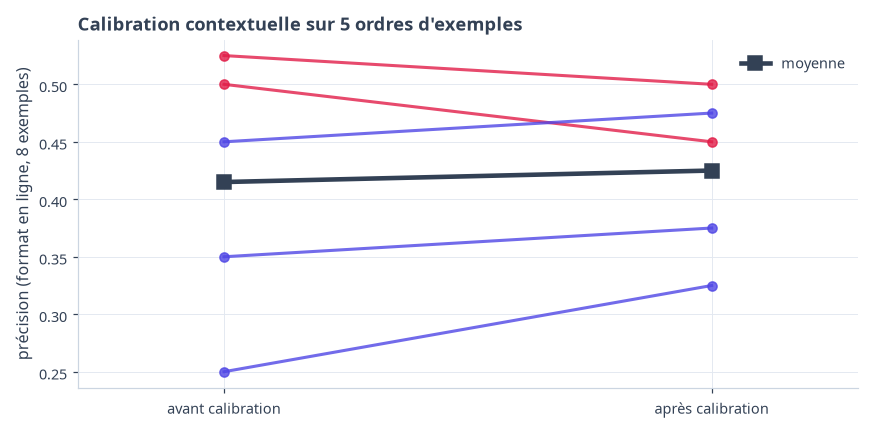

précision moyenne : 0.415 -> 0.425 ; écart-type entre ordres : 0.114 -> 0.073


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, r in calib.iterrows():
    ax.plot([0, 1], [r.avant, r.apres], "-o", color=INDIGO if r.apres >= r.avant else ROSE, alpha=0.8)
ax.plot([0, 1], [calib.avant.mean(), calib.apres.mean()], "-s", color=SLATE, lw=3, ms=9, label="moyenne")
ax.set_xticks([0, 1], ["avant calibration", "après calibration"])
ax.set_xlim(-0.3, 1.3)
ax.set_ylabel("précision (format en ligne, 8 exemples)")
ax.set_title("Calibration contextuelle sur 5 ordres d'exemples")
ax.legend()
finish(fig)
plt.show()
print(f"précision moyenne : {calib.avant.mean():.3f} -> {calib.apres.mean():.3f} ; "
      f"écart-type entre ordres : {calib.avant.std():.3f} -> {calib.apres.std():.3f}")

**Lecture.** La colonne `biais_cf` montre que, pour une entrée vide de sens, le prompt penche
nettement vers une ou deux étiquettes : c'est le biais que la calibration retire. Après
correction, le modèle utilise davantage d'étiquettes distinctes ; selon l'ordre, la précision
progresse plus ou moins, et peut parfois baisser (le biais mesuré sur « N/A » n'est qu'une
approximation du biais réel). La méthode ne remplace pas une meilleure présentation (les tours
de conversation du cours 1), mais elle est gratuite et réduit la sensibilité au prompt.

> **À retenir.** Un prompt few-shot induit un biais a priori sur les étiquettes, mesurable avec
> une entrée vide de sens et corrigeable par une simple division : 3 appels pour un prompt plus
> stable.

## Exercice 5.4 : Écrire le gabarit ChatML à la main et débusquer un gabarit bogué

**Énoncé.** (1) Écrire une fonction `chatml(messages)` qui reproduit exactement le gabarit de
Qwen2.5 (y compris le prompt système par défaut quand il n'y en a pas). La vérifier sur
plusieurs conversations contre `apply_chat_template`. (2) Une bibliothèque tierce utilise la
fonction `chatml_tiers` ci-dessous. Trouver son erreur **au niveau des tokens** et mesurer son
effet sur la précision de la tâche d'intentions.

In [8]:
def chatml_tiers(messages):
    """Gabarit « maison » d'une bibliothèque tierce (contient une erreur)."""
    out = ""
    for m in messages:
        out += f"<|im_start|>{m['role']}\n{m['content']}<|im_end|>"
    return out + "<|im_start|>assistant\n"

**Rappels.** Le gabarit ChatML (cours 2, section 2) : chaque tour s'écrit
`<|im_start|>rôle\ncontenu<|im_end|>\n` ; Qwen ajoute « You are Qwen, created by Alibaba Cloud.
You are a helpful assistant. » s'il n'y a pas de message système ; le prompt de génération est
`<|im_start|>assistant\n`. Le livre recommande d'imprimer le prompt final et de vérifier les
gabarits des outils tiers (section *System Prompt and User Prompt*).

**Solution (1).**

In [9]:
QWEN_DEFAUT = "You are Qwen, created by Alibaba Cloud. You are a helpful assistant."

def chatml(messages, add_generation_prompt=True):
    msgs = list(messages)
    if not msgs or msgs[0]["role"] != "system":
        msgs = [{"role": "system", "content": QWEN_DEFAUT}] + msgs
    out = "".join(f"<|im_start|>{m['role']}\n{m['content']}<|im_end|>\n" for m in msgs)
    return out + ("<|im_start|>assistant\n" if add_generation_prompt else "")

convs = [
    [{"role": "user", "content": "Salut !"}],
    [{"role": "system", "content": "Sois bref."}, {"role": "user", "content": "Une couleur ?"}],
    P.few_shot_messages(P.INTENT_DESCRIPTION, pool[:3], "Mon colis est perdu."),
]
for c in convs:
    assert chatml(c) == P.render_chat(c), "différence avec le gabarit officiel"
print("chatml() reproduit exactement apply_chat_template sur", len(convs), "conversations")

chatml() reproduit exactement apply_chat_template sur 3 conversations


**Solution (2).** On compare les deux rendus **token par token** avec `difflib` sur les listes
de tokens.

In [10]:
import difflib

c = convs[1]
t_ok = tok.tokenize(chatml(c))
t_bug = tok.tokenize(chatml_tiers(c))
for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, t_ok, t_bug).get_opcodes():
    if op != "equal":
        print(f"{op:8s} officiel {t_ok[i1:i2]}  ->  tiers {t_bug[j1:j2]}")

delete   officiel ['Ċ']  ->  tiers []
delete   officiel ['Ċ']  ->  tiers []


Sur cette conversation, le diff révèle que le saut de ligne `\n` après chaque `<|im_end|>`
manque. Sur une conversation **sans** message système, une seconde erreur apparaîtrait : le
gabarit tiers n'insère pas le prompt système par défaut de Qwen. Les deux sont **invisibles**
dans un affichage rapide. Mesurons leur effet.

In [11]:
shots8 = P.sample_shots(pool, 8, seed=0)
rows = []
for nom, f in [("officiel", chatml), ("tiers (bogué)", chatml_tiers)]:
    for k, shots in [(0, []), (8, shots8)]:
        preds = [P.predict_from_prefix(f(P.few_shot_messages(P.INTENT_DESCRIPTION, shots, x))) for x, _ in test]
        rows.append(dict(gabarit=nom, k=k, precision=np.mean([a == b for a, b in zip(preds, y_true)])))
pd.DataFrame(rows).pivot(index="gabarit", columns="k", values="precision").round(3)

k,0,8
gabarit,,
officiel,0.475,0.650
tiers (bogué),0.400,0.725


**Vérification.** Le tableau donne l'écart de précision dû au seul gabarit bogué. Quel que soit
son signe sur cette tâche, le point important est que le modèle reçoit une séquence qu'il n'a
jamais vue pendant son post-entraînement : le comportement devient imprévisible, et la panne est
silencieuse. Un test unitaire comme notre `assert` ci-dessus, exécuté à chaque mise à jour de
bibliothèque, aurait détecté l'erreur.

> **À retenir.** Un gabarit se teste comme du code : comparaison exacte au gabarit officiel,
> diff au niveau des tokens, et mesure de l'effet sur un jeu d'évaluation.

## Exercice 5.5 : Budget de contexte, cache KV et requêtes simultanées

**Énoncé.** On sert un assistant RAG dont chaque requête comporte 20 documents de 500 tokens,
600 tokens d'instructions et d'historique, et génère 400 tokens.

1. Calculer la taille du cache KV d'une requête pour Qwen2.5-0.5B (24 couches, 2 têtes KV,
   $d_\text{tête} = 64$) et pour Qwen2.5-7B (28 couches, 4 têtes KV, $d_\text{tête} = 128$), en bf16.
2. Sur un GPU de 24 Go, avec les poids en bf16 (1 Go pour le 0,5 B, 15,2 Go pour le 7 B) et
   10 % de marge, combien de requêtes simultanées tiennent en mémoire ?
3. Même question si l'on ne garde que les 5 meilleurs documents (meilleure recherche, chapitre 6).

**Rappels.** $M_\text{KV} = 2\,L\,h_\text{KV}\,d_\text{tête}\,n\,b$ (cours 2, section 5). Le cache
doit contenir le prompt **et** les tokens générés. La mémoire disponible pour le cache est la
mémoire totale moins les poids et la marge.

**Solution.** $n = 20 \times 500 + 600 + 400 = 11\,000$ tokens. Pour le 0,5 B :
$2 \times 24 \times 2 \times 64 \times 2 = 12\,288$ octets par token, soit 135 Mo par requête.
Pour le 7 B : $2 \times 28 \times 4 \times 128 \times 2 = 57\,344$ octets par token, soit 631 Mo.

In [12]:
GPU = 24e9
modeles = {"Qwen2.5-0.5B": dict(L=24, h=2, d=64, poids=1.0e9), "Qwen2.5-7B": dict(L=28, h=4, d=128, poids=15.2e9)}
rows = []
for n_docs in [20, 5]:
    n = n_docs * 500 + 600 + 400
    for nom, m in modeles.items():
        kv = P.kv_cache_bytes(n, m["L"], m["h"], m["d"])
        dispo = GPU * 0.9 - m["poids"]
        rows.append(dict(documents=n_docs, tokens=n, modele=nom, kv_par_requete_Mo=kv / 1e6,
                         memoire_cache_Go=dispo / 1e9, requetes_simultanees=int(dispo // kv)))
budget = pd.DataFrame(rows)
budget.round(1)

,documents,tokens,modele,kv_par_requete_Mo,memoire_cache_Go,requetes_simultanees
0,20,11000,Qwen2.5-0.5B,135.2,20.6,152
1,20,11000,Qwen2.5-7B,630.8,6.4,10
2,5,3500,Qwen2.5-0.5B,43.0,20.6,478
3,5,3500,Qwen2.5-7B,200.7,6.4,31


**Vérification** graphique : nombre de requêtes simultanées en fonction de la longueur du
contexte.

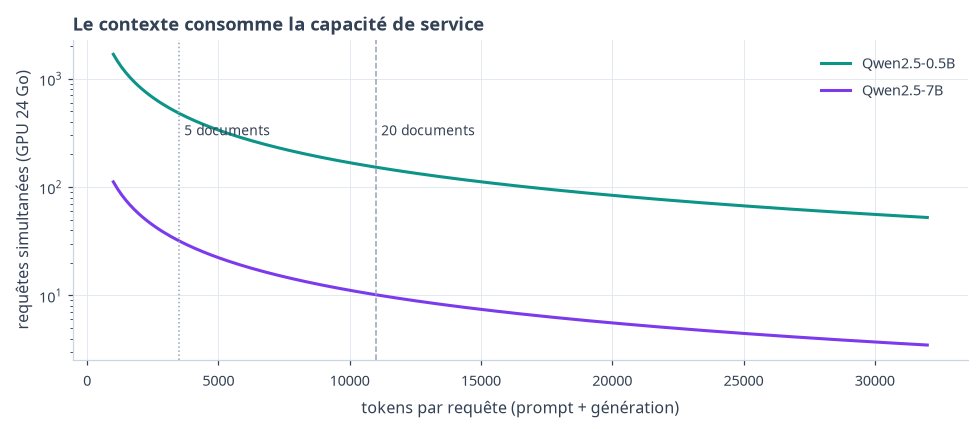

In [13]:
nn = np.linspace(1000, 32000, 200)
fig, ax = plt.subplots(figsize=(9, 4))
for (nom, m), c in zip(modeles.items(), [TEAL, VIOLET]):
    dispo = GPU * 0.9 - m["poids"]
    ax.plot(nn, dispo / P.kv_cache_bytes(nn, m["L"], m["h"], m["d"]), color=c, label=nom)
for n_docs, ls in [(20, "--"), (5, ":")]:
    ax.axvline(n_docs * 500 + 1000, color=GRAY, ls=ls, lw=1)
    ax.text(n_docs * 500 + 1200, 300, f"{n_docs} documents", fontsize=9, color=SLATE)
ax.set_yscale("log")
ax.set_xlabel("tokens par requête (prompt + génération)")
ax.set_ylabel("requêtes simultanées (GPU 24 Go)")
ax.set_title("Le contexte consomme la capacité de service")
ax.legend()
finish(fig)
plt.show()

**Lecture.** Le nombre de requêtes simultanées est inversement proportionnel à la longueur du
contexte : diviser par 4 le nombre de documents multiplie presque par 3 la capacité (la partie
fixe du prompt pèse). Pour le 7 B, le cache KV d'une seule requête RAG longue pèse plus d'un
demi-gigaoctet : la longueur de contexte se paie directement en débit. D'où l'intérêt de bien
**choisir** ce qu'on met dans le contexte (chapitre 6) plutôt que de remplir la fenêtre, et
des optimisations du chapitre 9 (quantification du cache, attention paginée).

> **À retenir.** Mémoire de cache KV = 2 x couches x têtes KV x dimension de tête x tokens x
> octets. À mémoire fixe, chaque token de contexte en plus réduit le nombre de requêtes servies
> en parallèle.

## Exercice 5.6 : « Perdu au milieu » : test statistique et remède

**Énoncé.** (1) Avec la botte de foin à leurres (`make_kv_haystack`, 80 paires), comparer le
taux de réussite quand l'aiguille est au **début** et au **milieu**, sur 16 essais chacun. La
différence est-elle statistiquement significative (test exact de Fisher) ? (2) Le livre
rapporte que les instructions placées au début ou à la fin sont mieux suivies. Tester un remède :
poser la question **avant et après** le document, au lieu de seulement après.

**Rappels.** Courbe en U du test de l'aiguille (cours 2, section 6). Pour comparer deux
proportions sur de petits échantillons, le **test exact de Fisher** sur le tableau 2 x 2
(réussites / échecs x position) donne une p-valeur sans approximation normale.

**Solution (1).**

In [14]:
def essai(n_pairs, depth, seed, question_avant=False):
    hay, q, ans = P.make_kv_haystack(n_pairs, depth, seed)
    if question_avant:
        prompt = f"Question : {q}\n\n" + P.niah_prompt(hay, q)
    else:
        prompt = P.niah_prompt(hay, q)
    out = llm.chat(prompt, max_new_tokens=30)
    return ans in out

N = 16
res = {(d, qa): [essai(80, d, s, qa) for s in range(N)] for d in [0.0, 0.5, 1.0] for qa in [False, True]}
debut, milieu = res[(0.0, False)], res[(0.5, False)]
table = [[sum(debut), N - sum(debut)], [sum(milieu), N - sum(milieu)]]
odds, p_fisher = stats.fisher_exact(table, alternative="greater")
print(f"début : {sum(debut)}/{N}  |  milieu : {sum(milieu)}/{N}  |  p-valeur (Fisher unilatéral) = {p_fisher:.4f}")

début : 16/16  |  milieu : 5/16  |  p-valeur (Fisher unilatéral) = 0.0000


**Solution (2)** et **vérification** graphique.

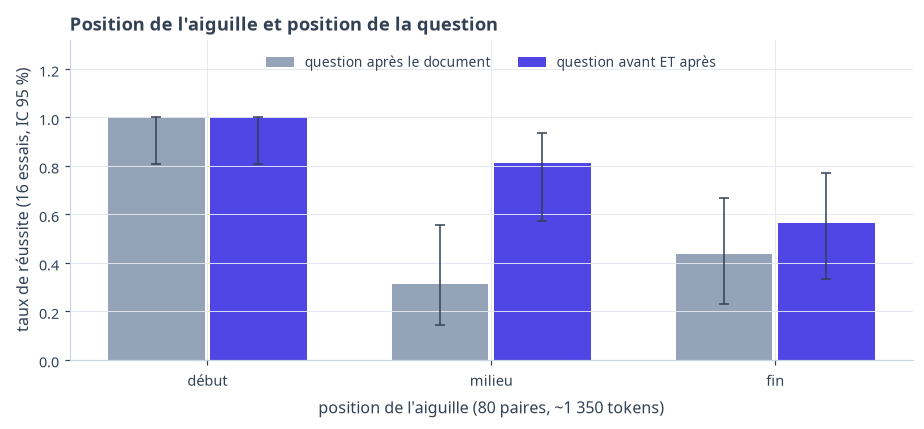

milieu, question avant+après : 13/16 contre 5/16 ; p (Fisher) = 0.006


In [15]:
fig, ax = plt.subplots(figsize=(8.5, 4))
for j, (qa, c, lab) in enumerate([(False, GRAY, "question après le document"), (True, INDIGO, "question avant ET après")]):
    vals = [np.mean(res[(d, qa)]) for d in [0.0, 0.5, 1.0]]
    errs = np.array([P.wilson_interval(sum(res[(d, qa)]), N) for d in [0.0, 0.5, 1.0]])
    x = np.arange(3) + (j - 0.5) * 0.36
    ax.bar(x, vals, 0.34, color=c, label=lab)
    ax.errorbar(x, vals, yerr=[np.array(vals) - errs[:, 0], errs[:, 1] - np.array(vals)], fmt="none",
                ecolor=SLATE, capsize=3, lw=1)
ax.set_xticks(range(3), ["début", "milieu", "fin"])
ax.set_ylim(0, 1.32)
ax.set_ylabel(f"taux de réussite ({N} essais, IC 95 %)")
ax.set_xlabel("position de l'aiguille (80 paires, ~1 350 tokens)")
ax.set_title("Position de l'aiguille et position de la question")
ax.legend(loc="upper center", fontsize=9, ncol=2)
finish(fig)
plt.show()
_, p2 = stats.fisher_exact([[sum(res[(0.5, True)]), N - sum(res[(0.5, True)])], [sum(milieu), N - sum(milieu)]],
                           alternative="greater")
print(f"milieu, question avant+après : {sum(res[(0.5, True)])}/{N} contre {sum(milieu)}/{N} ; p (Fisher) = {p2:.3f}")

**Lecture.** (1) Avec 16 essais par position, l'avantage du début sur le milieu est massif et
la p-valeur de Fisher le confirme (sauf exécution très atypique) : l'effet « perdu au milieu »
n'est pas un artefact du hasard. (2) Annoncer la question **avant** le document permet au modèle
de « savoir quoi chercher » pendant qu'il lit (dans un modèle causal, les tokens du document ne
voient que ce qui les précède) ; l'effet mesuré sur le milieu est à lire avec son intervalle de
confiance, car 16 essais ne détectent que des effets importants.

> **À retenir.** Un effet de position se teste comme n'importe quelle hypothèse : tableau 2 x 2
> et test exact pour les petits échantillons. Dans un modèle causal, placer la question avant le
> contexte aide le modèle à lire « orienté ».

In [16]:
llm.free_gpu()